<a href="https://colab.research.google.com/github/arjunnamburi/ml_death_overs_ipl/blob/main/notebooks/site_export.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ===== W0. Setup (COPY-PASTE) =====
import json, os
import numpy as np
import pandas as pd
import xgboost as xgb
from google.colab import drive

drive.mount('/content/drive')
DATA = '/content/drive/MyDrive/IPL PROJECT ALL DOCS/data/'
OUT = DATA + 'site/'                                   # everything the website reads
os.makedirs(OUT + 'replay', exist_ok=True)
os.makedirs(OUT + 'img', exist_ok=True)

df = pd.read_parquet(DATA + 'ipl_features.parquet')
with open(DATA + 'feature_list.json') as f: meta = json.load(f)
FEATURES, CAT_FEATURES = meta['features'], meta['categorical']
HIST = sum(meta['hist_features'].values(), [])
FEAT_HIST = list(FEATURES) + HIST                      # the 87 X-hist inputs, frozen order
NAMES = ['0', '1', '2', '3', '4', '6', 'W']
K = len(NAMES)

def pick(*cands):
    """The first of these column names that exists, or None."""
    return next((c for c in cands if c in df.columns), None)
COL = {'team_bat':   pick('batting_team', 'bat_team', 'team_batting', 'batting_side'),
       'team_bowl':  pick('bowling_team', 'bowl_team', 'team_bowling', 'bowling_side'),
       'extra_type': pick('extra_type', 'extras_type', 'extra_kind', 'extras_kind')}
print('optional columns found:', COL)

# every delivery, in order (as in the error analysis)
df['score_before'] = df.groupby(['match_id', 'innings'])['ball_runs_total'].cumsum() - df['ball_runs_total']
df['legal'] = df['y'] >= 0
nxt_w = df.groupby(['match_id', 'innings'])['c_team_wickets'].shift(-1)
df['wkt_here'] = np.where(nxt_w.notna(), nxt_w - df['c_team_wickets'], df['y'] == 6).astype(int)

# legal balls with the same category codes as the training run
d = df[(df['y'] >= 0) & df['split'].isin(['train', 'val', 'test'])].copy()
d['y'] = d['y'].astype(int)
for c in CAT_FEATURES:
    if not isinstance(d[c].dtype, pd.CategoricalDtype):
        d[c] = d[c].astype('category')

B = pd.read_parquet(DATA + 'bundle_2026.parquet')
v = d.loc[B.index]                                     # 2026 feature rows, in bundle order
y = B['y'].to_numpy().astype(int)
i = np.arange(len(y))
P = {m: B[[f'p{t}_{k}' for k in range(K)]].to_numpy() for m, t in [('xgb', 'x'), ('lr', 'l'), ('b1', 'b1')]}
L = {m: -np.log(np.clip(p[i, y], 1e-15, 1)) for m, p in P.items()}
match, death = B['match_id'].to_numpy(), B['death'].to_numpy()
pos = pd.Series(np.arange(len(B)), index=B.index)      # bundle row of each legal 2026 ball

print('1. rows line up:', (v['y'].to_numpy() == y).all())                                  # expect True
print('2. death log-loss xgb / lr / b1:', *[round(L[m][death].mean(), 4) for m in L])     # expect 1.568 1.5764 1.6017
print('3. 2026 matches:', len(np.unique(match)), '| death balls:', int(death.sum()))      # expect 71 | 3583
print('4. death = from over 16:', (v.loc[death, 'c_team_balls'] >= 90).all(),
      (v.loc[~death, 'c_team_balls'] < 90).all())                                          # expect True True

Mounted at /content/drive
optional columns found: {'team_bat': 'batting_team', 'team_bowl': 'bowling_team', 'extra_type': None}
1. rows line up: True
2. death log-loss xgb / lr / b1: 1.568 1.5764 1.6017
3. 2026 matches: 71 | death balls: 3583
4. death = from over 16: True True


In [2]:
# ===== W1. Replay matches by rule (COPY-PASTE) =====
RULE = ("Four 2026 matches, picked by a rule written on Nov 4 before any per-match death result was looked at. "
        "Eligible: matches where both innings reached over 16. Gain = XGBoost's mean death-ball log-loss minus B1's, "
        "over both innings. Picked in this order, each from the matches not yet picked: XGBoost's best (most negative gain); "
        "XGBoost's worst (most positive gain); typical (gain closest to the median of all eligible matches); "
        "close chase (a chase that reached the 20th over, with the smallest gap between the two innings totals; "
        "ties go to the earlier match).")

# eligibility and gain per match (death balls only)
dm_ = pd.DataFrame({'match_id': match[death], 'inn': v.loc[death, 'innings'].to_numpy(),
                    'gain': (L['xgb'] - L['b1'])[death]})
n_inn = dm_.groupby('match_id')['inn'].nunique()
g = dm_.groupby('match_id')['gain'].agg(['mean', 'size']).loc[n_inn[n_inn == 2].index]
print('eligible matches:', len(g), 'of', len(n_inn))

# chase facts from every 2026 delivery
t = df[df['split'] == 'test']
tot = t.groupby(['match_id', 'innings'])['ball_runs_total'].sum().unstack()
inn2 = t[t['innings'] == 2]
chase = pd.DataFrame({'first': tot[1], 'chase': tot[2],
                      'reached_20th': inn2.groupby('match_id')['c_team_balls'].max() >= 114,
                      'target': inn2.groupby('match_id')['runs_target'].first()})
chase.index.name = 'match_id'
chase['reached_20th'] = chase['reached_20th'].fillna(False).astype(bool)
chase['margin'] = (chase['chase'] - chase['first']).abs()
print('target = first-innings total + 1 in', f"{100 * (chase['target'] == chase['first'] + 1).mean():.0f}% of matches")   # expect 100%

rest, picked = g.copy(), {}
def take(role, mid):
    picked[role] = mid
    rest.drop(index=mid, inplace=True)
take('XGBoost best', rest['mean'].idxmin())
take('XGBoost worst', rest['mean'].idxmax())
take('typical', (rest['mean'] - g['mean'].median()).abs().idxmin())
cc = chase[chase.index.isin(rest.index) & chase['reached_20th']].reset_index().sort_values(['margin', 'match_id'])
if len(cc):
    take('close chase', cc['match_id'].iloc[0])
else:
    print('no eligible close chase: only 3 matches')

sel = pd.DataFrame({'role': list(picked), 'match_id': list(picked.values())}).set_index('match_id')
sel = sel.join(g.rename(columns={'mean': 'gain', 'size': 'death_balls'})).join(chase[['first', 'chase', 'margin', 'reached_20th']])
if COL['team_bat']:
    sel['first_bat'] = [t.loc[(t['match_id'] == m) & (t['innings'] == 1), COL['team_bat']].iloc[0] for m in sel.index]
    sel['chasing']   = [t.loc[(t['match_id'] == m) & (t['innings'] == 2), COL['team_bat']].iloc[0] for m in sel.index]
sel['venue'] = [str(t.loc[t['match_id'] == m, 'venue'].iloc[0]) for m in sel.index]
sel.to_csv(OUT + 'replay_matches.csv')
print(sel.round(4).to_string())

eligible matches: 66 of 71
target = first-innings total + 1 in 100% of matches
                   role    gain  death_balls  first  chase  margin  reached_20th              first_bat                      chasing                                                                  venue
match_id                                                                                                                                                                                                   
1535464    XGBoost best -0.1721           52    214    219       5         False       Rajasthan Royals               Gujarat Titans     Maharaja Yadavindra Singh International Cricket Stadium, Mullanpur
1529310   XGBoost worst  0.0927           60    255    200      55          True    Sunrisers Hyderabad  Royal Challengers Bengaluru                              Rajiv Gandhi International Stadium, Uppal
1529291         typical -0.0335           45    155    159       4         False         Delhi Capitals  

In [3]:
# ===== W2. Per-feature pushes, 2026 death balls (COPY-PASTE; push formula from E3b) =====
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True); E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

bst = xgb.Booster(); bst.load_model(DATA + 'xgb_X-hist_2026.json')
bst.set_param({'device': 'cuda'})
vd = v.loc[death]                                      # 3583 death balls, bundle order
yd = y[death]; idd = np.arange(len(yd))
dmat = xgb.DMatrix(vd[FEAT_HIST], enable_categorical=True)
margin = bst.predict(dmat, output_margin=True)         # (n, 7) raw class scores
phi = bst.predict(dmat, pred_contribs=True)            # (n, 7, 88): last column = bias
PXm = softmax(margin)
print('1. same model as the bundle:', f"{np.abs(PXm - P['xgb'][death]).max():.1e}")      # expect below 1e-5

F = phi[:, :, :-1]
push = F[idd, yd, :] - np.einsum('nk,nkf->nf', PXm, F)
PUSH = pd.DataFrame(push, columns=FEAT_HIST, index=vd.index)
P0 = softmax(phi[:, :, -1])
kl = (PXm * np.log(PXm / P0)).sum(axis=1)
exact = np.log(PXm[idd, yd]) - np.log(P0[idd, yd]) - kl
print('2. pushes add up exactly:', f'{np.abs(push.sum(axis=1) - exact).max():.1e}')      # expect below 1e-3
PUSH.to_parquet(DATA + 'push_death_2026.parquet')

def fval(c, x):
    """A feature value ready for the page."""
    if pd.isna(x): return None
    return str(x) if c in CAT_FEATURES else round(float(x), 3)

def why(idx, n):
    """The n features with the largest |push| on this ball."""
    s = PUSH.loc[idx]
    top = s.reindex(s.abs().sort_values(ascending=False).index[:n])
    return [{'f': f, 'value': fval(f, vd.at[idx, f]), 'push': round(float(p), 3)} for f, p in top.items()]

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [12:59:07] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  return func(**kwargs)
/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [12:59:07] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  return func(**kwargs)


1. same model as the bundle: 1.2e-07
2. pushes add up exactly: 2.5e-06


In [4]:
# ===== W3. Feature list for the labels (COPY-PASTE) =====
for c in FEAT_HIST:
    s = vd[c]
    if isinstance(s.dtype, pd.CategoricalDtype):
        ex = 'categories: ' + ', '.join(map(str, s.cat.categories[:8]))
    else:
        q = pd.to_numeric(s, errors='coerce').astype(float).quantile([0.1, 0.5, 0.9]).round(2).tolist()
        ex = f'10/50/90%: {q}  missing {s.isna().mean():.0%}'
    print(f'{c:32s} {ex}')

innings                          10/50/90%: [1.0, 1.0, 2.0]  missing 0%
bat_pos                          10/50/90%: [3.0, 6.0, 9.0]  missing 0%
non_striker_pos                  10/50/90%: [3.0, 6.0, 9.0]  missing 0%
runs_target                      10/50/90%: [157.0, 206.0, 248.0]  missing 58%
c_team_runs                      10/50/90%: [125.0, 167.0, 211.0]  missing 0%
c_team_balls                     10/50/90%: [92.0, 103.0, 115.0]  missing 0%
c_team_wickets                   10/50/90%: [3.0, 5.0, 8.0]  missing 0%
c_batter_runs                    10/50/90%: [0.0, 15.0, 63.0]  missing 0%
c_batter_balls                   10/50/90%: [1.0, 11.0, 39.0]  missing 0%
c_bowler_runs                    10/50/90%: [14.0, 28.0, 43.0]  missing 0%
c_bowler_wickets                 10/50/90%: [0.0, 1.0, 2.0]  missing 0%
c_bowler_balls                   10/50/90%: [12.0, 19.0, 22.0]  missing 0%
batter_hand                      categories: LHB, RHB
bowler_cat                       categories: LA_Orthod

In [7]:
# ===== W4. Replay export (COPY-PASTE) =====
def r4(a): return [round(float(x), 4) for x in a]

def extra_label(row, next_is_free_hit):
    if COL['extra_type']:
        return str(row[COL['extra_type']])
    return 'no-ball' if next_is_free_hit else 'wide'      # a no-ball makes the next ball a free hit

def team(M, inn, key):
    if not COL[key]: return None
    s = M.loc[M['innings'] == inn, COL[key]]
    return str(s.iloc[0]) if len(s) else None

index = []
for role, mid in picked.items():
    M = df[df['match_id'] == mid]
    out = {'match_id': int(mid), 'role': role, 'rule': RULE, 'venue': str(M['venue'].iloc[0]),
           'models': {'xgb': 'XGBoost (X-hist)', 'lr': 'Logistic regression (B2-hist +V)', 'b1': 'Scorecard baseline (B1)'},
           'classes': NAMES, 'innings': []}
    for inn, I in M.groupby('innings', sort=True):
        I = I[I['c_team_balls'] >= 90]                 # from over 16 (90 legal balls already bowled)
        if I.empty:
            continue
        first, inn = I.iloc[0], int(inn)
        target = int(first['runs_target']) if inn == 2 else None
        fh_next = I['is_free_hit'].shift(-1).fillna(0).astype(bool).to_numpy()
        cum, balls = {m: 0.0 for m in P}, []
        for j, (idx, r) in enumerate(I.iterrows()):
            b = int(r['c_team_balls'])
            row = {'over': f'{b // 6}.{b % 6 + 1}', 'batter': str(r['batter']), 'bowler': str(r['bowler']),
                   'score': f"{int(r['score_before'])}/{int(r['c_team_wickets'])}",
                   'runs': int(r['ball_runs_total']), 'wicket': bool(r['wkt_here'])}
            if inn == 2:
                row.update(need=int(target - r['score_before']), balls_left=120 - b)
            if not r['legal']:
                row.update(legal=False, extra=extra_label(r, fh_next[j]))
            else:
                k = pos[idx]
                for m in P:
                    cum[m] += float(L[m][k])
                row.update(legal=True, free_hit=bool(r['is_free_hit']), new_batter=int(r['c_batter_balls']) == 0,
                           outcome=NAMES[y[k]], p={m: r4(P[m][k]) for m in P},
                           loss={m: round(float(L[m][k]), 4) for m in P}, cum={m: round(cum[m], 4) for m in P},
                           gap_cum=round(cum['xgb'] - cum['b1'], 4),
                           x_minus_b1=round(float(L['xgb'][k] - L['b1'][k]), 4), why=why(idx, 3))
            balls.append(row)
        legal = [x for x in balls if x['legal']]
        for x in sorted(legal, key=lambda x: -abs(x['x_minus_b1']))[:5]:
            x['key'] = True
        out['innings'].append({'innings': inn, 'batting': team(M, inn, 'team_bat'), 'bowling': team(M, inn, 'team_bowl'),
                               'start': {'runs': int(first['score_before']), 'wkts': int(first['c_team_wickets'])},
                               'target': target, 'balls': balls})
        print(f"{mid} ({role}) inn {inn}: {len(balls)} deliveries, {len(legal)} legal, "
              f"{sum(x.get('free_hit', False) for x in legal)} free hits | "
              f"total loss xgb {cum['xgb']:.2f}  lr {cum['lr']:.2f}  b1 {cum['b1']:.2f}  gap {cum['xgb'] - cum['b1']:+.2f}")
    with open(OUT + f'replay/{int(mid)}.json', 'w') as f:
        json.dump(out, f, separators=(',', ':'), default=lambda o: o.item())
    index.append({'match_id': int(mid), 'role': role, 'venue': out['venue'],
                  'teams': [x['batting'] for x in out['innings']]})

with open(OUT + 'replay/index.json', 'w') as f:
    json.dump({'rule': RULE, 'matches': index}, f, indent=1)
n_exp = sum(int(sel.loc[m, 'death_balls']) for m in sel.index)
print('legal death balls exported:', sum(len([x for x in json.load(open(OUT + f'replay/{m}.json'))['innings'][q]['balls'] if x['legal']])
      for m in sel.index for q in range(2)), '| expected', n_exp)                       # the two numbers should match

1535464 (XGBoost best) inn 1: 30 deliveries, 30 legal, 0 free hits | total loss xgb 47.19  lr 46.70  b1 53.52  gap -6.34
1535464 (XGBoost best) inn 2: 23 deliveries, 22 legal, 0 free hits | total loss xgb 33.59  lr 34.63  b1 36.20  gap -2.61
1529310 (XGBoost worst) inn 1: 34 deliveries, 30 legal, 0 free hits | total loss xgb 51.45  lr 51.23  b1 48.65  gap +2.80
1529310 (XGBoost worst) inn 2: 30 deliveries, 30 legal, 0 free hits | total loss xgb 48.80  lr 46.99  b1 46.03  gap +2.76
1529291 (typical) inn 1: 32 deliveries, 30 legal, 0 free hits | total loss xgb 41.67  lr 42.07  b1 42.99  gap -1.32
1529291 (typical) inn 2: 16 deliveries, 15 legal, 0 free hits | total loss xgb 23.53  lr 23.58  b1 23.71  gap -0.19
1529281 (close chase) inn 1: 32 deliveries, 30 legal, 0 free hits | total loss xgb 41.74  lr 44.32  b1 47.47  gap -5.73
1529281 (close chase) inn 2: 33 deliveries, 30 legal, 1 free hits | total loss xgb 53.22  lr 53.90  b1 52.31  gap +0.91
legal death balls exported: 217 | expected

In [6]:
# ===== W5. Worst-balls lists (COPY-PASTE) =====
dd = pd.DataFrame({'idx': B.index[death], 'outcome': np.array(NAMES)[yd],
                   **{'L_' + m: L[m][death] for m in P}})
dd['X_minus_B1'] = dd['L_xgb'] - dd['L_b1']
LISTS = {'top10_loss':       dd.nlargest(10, 'L_xgb')['idx'],
         'top10_vs_B1':      dd.nlargest(10, 'X_minus_B1')['idx'],
         'top3_per_outcome': dd.sort_values('L_xgb', ascending=False).groupby('outcome', sort=False).head(3)
                               .sort_values(['outcome', 'L_xgb'], ascending=[True, False])['idx']}
member = {}
for name, ids in LISTS.items():
    for rank, ix in enumerate(ids, 1):
        member.setdefault(ix, {})[name] = rank

rec = []
for ix, lists in member.items():
    k, r = pos[ix], df.loc[ix]
    b = int(r['c_team_balls'])
    item = {'id': int(ix), 'lists': lists, 'match_id': int(r['match_id']), 'innings': int(r['innings']),
            'batting': str(r[COL['team_bat']]) if COL['team_bat'] else None,
            'over': f'{b // 6}.{b % 6 + 1}', 'score': f"{int(r['score_before'])}/{int(r['c_team_wickets'])}",
            'batter': str(r['batter']), 'bowler': str(r['bowler']),
            'free_hit': bool(r['is_free_hit']), 'new_batter': int(r['c_batter_balls']) == 0,
            'outcome': NAMES[y[k]], 'p': {m: r4(P[m][k]) for m in P},
            'p_actual_pct': {m: round(100 * float(P[m][k, y[k]]), 2) for m in P},
            'loss': {m: round(float(L[m][k]), 4) for m in P}, 'why': why(ix, 5), 'hypothesis': ''}
    if int(r['innings']) == 2:
        item.update(need=int(r['runs_target'] - r['score_before']), balls_left=120 - b)
    rec.append(item)

with open(OUT + 'worst_balls_death_2026.json', 'w') as f:
    json.dump({'lists': {n: [int(x) for x in ids] for n, ids in LISTS.items()}, 'balls': rec}, f, indent=1)

flat = pd.DataFrame([{**{k: v_ for k, v_ in x.items() if k not in ('p', 'p_actual_pct', 'loss', 'why', 'lists')},
                      **{f'{n}_rank': x['lists'].get(n) for n in LISTS},
                      **{f'p_{m}_%': x['p_actual_pct'][m] for m in P},
                      'pushes': '; '.join(f"{w['f']}={w['value']} ({w['push']:+.2f})" for w in x['why'])} for x in rec])
flat.to_csv(OUT + 'worst_balls_death_2026.csv', index=False)
print(len(rec), 'distinct balls across the three lists')                                  # at most 41

show = ['match_id', 'innings', 'over', 'score', 'batter', 'bowler', 'free_hit', 'outcome', 'p_xgb_%', 'p_lr_%', 'p_b1_%']
for n in LISTS:
    print(f'\n--- {n} ---')
    print(flat.dropna(subset=[f'{n}_rank']).sort_values(f'{n}_rank')[show].to_string(index=False))

29 distinct balls across the three lists

--- top10_loss ---
 match_id  innings over score              batter            bowler  free_hit outcome  p_xgb_%  p_lr_%  p_b1_%
  1529305        2 15.2 143/3            AR Patel          AF Milne     False       3     0.08    0.15    0.28
  1529296        1 15.2 154/6        Himmat Singh        Noor Ahmad     False       3     0.11    0.17    0.27
  1529306        2 16.4 146/3 Nithish Kumar Reddy          A Kamboj     False       3     0.14    0.16    0.28
  1529308        2 18.3 141/6              AS Roy          WG Jacks     False       3     0.15    0.19    0.24
  1535462        1 19.3 242/5           JM Sharma M Prasidh Krishna     False       3     0.15    0.17    0.26
  1529306        1 18.4 164/6           AJ Hosein     Sakib Hussain     False       3     0.16    0.18    0.27
  1529312        1 19.3 192/8            N Burger         SN Thakur     False       3     0.29    0.17    0.33
  1529268        1 17.6 166/8        Kartik Tyagi  

In [8]:
# ===== W5b. Pushes away from what happened, per listed ball (COPY-PASTE) =====
# feature -> group, the same rules as A1, with player type split out of situation
HNAME = {'8_batter': 'batter history', '9_bowler': 'bowler history', '10_base': 'matchup & base rates',
         '11_venue_season': 'venue & season'}
GROUP_OF, taken = {}, set()
def assign(name, rule):
    for c in FEATURES:
        if c not in taken and rule(c):
            taken.add(c); GROUP_OF[c] = name
assign('delivery',     lambda c: c in ('is_free_hit', 'prev_ball_outcome'))
assign('chase',        lambda c: any(k in c for k in ('required', 'need', 'pressure', 'runs_target')))
assign('partnership',  lambda c: 'partnership' in c or 'non_striker' in c or 'nonstriker' in c
                                 or c.startswith('ns_') or 'left_right' in c)
assign('striker',      lambda c: c.startswith('batter_') and c != 'batter_hand')
assign('bowler spell', lambda c: (c.startswith('bowler_') and c != 'bowler_cat') or 'spell' in c
                                 or 'since_last_bowled' in c)
assign('momentum',     lambda c: any(k in c for k in ('last6', 'last12', 'since', 'this_over')))
assign('player type',  lambda c: c in ('batter_hand', 'bowler_cat', 'matchup_type'))
assign('scorecard',    lambda c: True)
for k, cols in meta['hist_features'].items():
    for c in cols:
        GROUP_OF[c] = HNAME.get(k, k)
print('groups:', pd.Series(GROUP_OF).value_counts().to_dict())   # expect scorecard 17, momentum 12, batter history 9 ...

with open(OUT + 'worst_balls_death_2026.json') as f:
    WB = json.load(f)
for b in WB['balls']:
    s = PUSH.loc[b['id']]
    b['pushed_away'] = [{'f': f, 'value': fval(f, vd.at[b['id'], f]), 'push': round(float(p), 3)}
                        for f, p in s.nsmallest(3).items()]
    g = s.groupby(GROUP_OF).sum().sort_values()
    b['group_push'] = {k: round(float(v), 3) for k, v in g.items()}
with open(OUT + 'worst_balls_death_2026.json', 'w') as f:
    json.dump(WB, f, indent=1, default=lambda o: o.item())

extra = pd.DataFrame([{'id': b['id'],
                       'pushed_away': '; '.join(f"{w['f']}={w['value']} ({w['push']:+.2f})" for w in b['pushed_away']),
                       'worst_group': next(iter(b['group_push'])),
                       'worst_group_push': next(iter(b['group_push'].values())),
                       'groups': '; '.join(f'{k} {v:+.2f}' for k, v in b['group_push'].items())} for b in WB['balls']])
flat = pd.read_csv(OUT + 'worst_balls_death_2026.csv').drop(columns=['pushed_away', 'worst_group', 'worst_group_push',
                                                                     'groups'], errors='ignore').merge(extra, on='id')
flat.to_csv(OUT + 'worst_balls_death_2026.csv', index=False)

pd.set_option('display.max_colwidth', None)
for _, r in flat.iterrows():
    print(f"\n{r['batter']} vs {r['bowler']} | {r['over']} {r['score']} | outcome {r['outcome']} | "
          f"p XGB {r['p_xgb_%']}% LR {r['p_lr_%']}% B1 {r['p_b1_%']}%")
    print('   pushed away:', r['pushed_away'])
    print('   groups     :', r['groups'])

groups: {'scorecard': 17, 'momentum': 12, 'batter history': 9, 'bowler history': 8, 'venue & season': 7, 'bowler spell': 7, 'partnership': 7, 'chase': 6, 'striker': 5, 'matchup & base rates': 4, 'player type': 3, 'delivery': 2}

AR Patel vs AF Milne | 15.2 143/3 | outcome 3 | p XGB 0.08% LR 0.15% B1 0.28%
   pushed away: bat_six_pct_3s=0.065 (-0.30); bat_out_pct_3s=0.057 (-0.15); venue_bdry_pct_3s=0.239 (-0.14)
   groups     : batter history -0.55; venue & season -0.42; scorecard -0.19; chase -0.10; bowler history -0.10; matchup & base rates -0.09; delivery -0.07; bowler spell -0.02; momentum -0.02; player type +0.01; partnership +0.01; striker +0.08

Himmat Singh vs Noor Ahmad | 15.2 154/6 | outcome 3 | p XGB 0.11% LR 0.17% B1 0.27%
   pushed away: bat_six_pct_3s=0.077 (-0.31); batter_bdry_run_pct=1.0 (-0.17); venue_bdry_pct_3s=0.184 (-0.15)
   groups     : batter history -0.45; venue & season -0.34; striker -0.20; scorecard -0.09; momentum -0.07; matchup & base rates -0.07; bowler hi

In [9]:
# ===== W6a. Figure style (COPY-PASTE) =====
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import Image, display

THEME = {
    'light': dict(surface='#fcfcfb', ink='#0b0b0b', ink2='#52514e', grid='#e6e5e0', zero='#8a8984', data='#3b3a37',
                  model={'xgb': '#2a78d6', 'lr': '#eb6834', 'b1': '#1baf7a'},
                  phase=['#86b6ef', '#2a78d6', '#104281'], band='#f0efec'),
    'dark':  dict(surface='#1a1a19', ink='#f0efec', ink2='#c3c2b7', grid='#33332f', zero='#8a8984', data='#d6d5cf',
                  model={'xgb': '#3987e5', 'lr': '#d95926', 'b1': '#199e70'},
                  phase=['#184f95', '#3987e5', '#9ec5f4'], band='#262624'),
}
MODEL_NAME = {'xgb': 'XGBoost', 'lr': 'Logistic regression', 'b1': 'Scorecard baseline (B1)'}
MARKER = {'xgb': 'o', 'lr': 's', 'b1': '^'}

def use_theme(mode):
    T = THEME[mode]
    mpl.rcParams.update({
        'figure.facecolor': T['surface'], 'axes.facecolor': T['surface'], 'savefig.facecolor': T['surface'],
        'text.color': T['ink'], 'axes.labelcolor': T['ink2'], 'xtick.color': T['ink2'], 'ytick.color': T['ink2'],
        'axes.edgecolor': T['grid'], 'axes.grid': True, 'grid.color': T['grid'], 'grid.linewidth': 0.8,
        'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
        'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
        'font.size': 10, 'legend.frameon': False, 'lines.linewidth': 1.5, 'lines.markersize': 6,
        'svg.fonttype': 'none'})
    return T

def render(draw, name):
    """draw(T) -> fig. Saves light and dark SVG + PNG, shows the light PNG."""
    for mode in ('light', 'dark'):
        fig = draw(use_theme(mode))
        for ext in ('svg', 'png'):
            fig.savefig(OUT + f'img/{name}_{mode}.{ext}', dpi=200, bbox_inches='tight')
        plt.close(fig)
    display(Image(OUT + f'img/{name}_light.png', width=760))

def interval_marks(ax, yv, mid, lo, hi, color, filled, marker='o'):
    """Dot + 95% interval. Filled = interval excludes 0; hollow = it doesn't."""
    for yy, m, l, h, f in zip(yv, mid, lo, hi, filled):
        ax.plot([l, h], [yy, yy], color=color, lw=1.5, solid_capstyle='round')
        ax.plot(m, yy, marker=marker, ms=7, color=color, mfc=color if f else mpl.rcParams['axes.facecolor'], mew=1.5)

six %: training 2008-2024 5.1 | 2025 7.9 | 2026 8.5


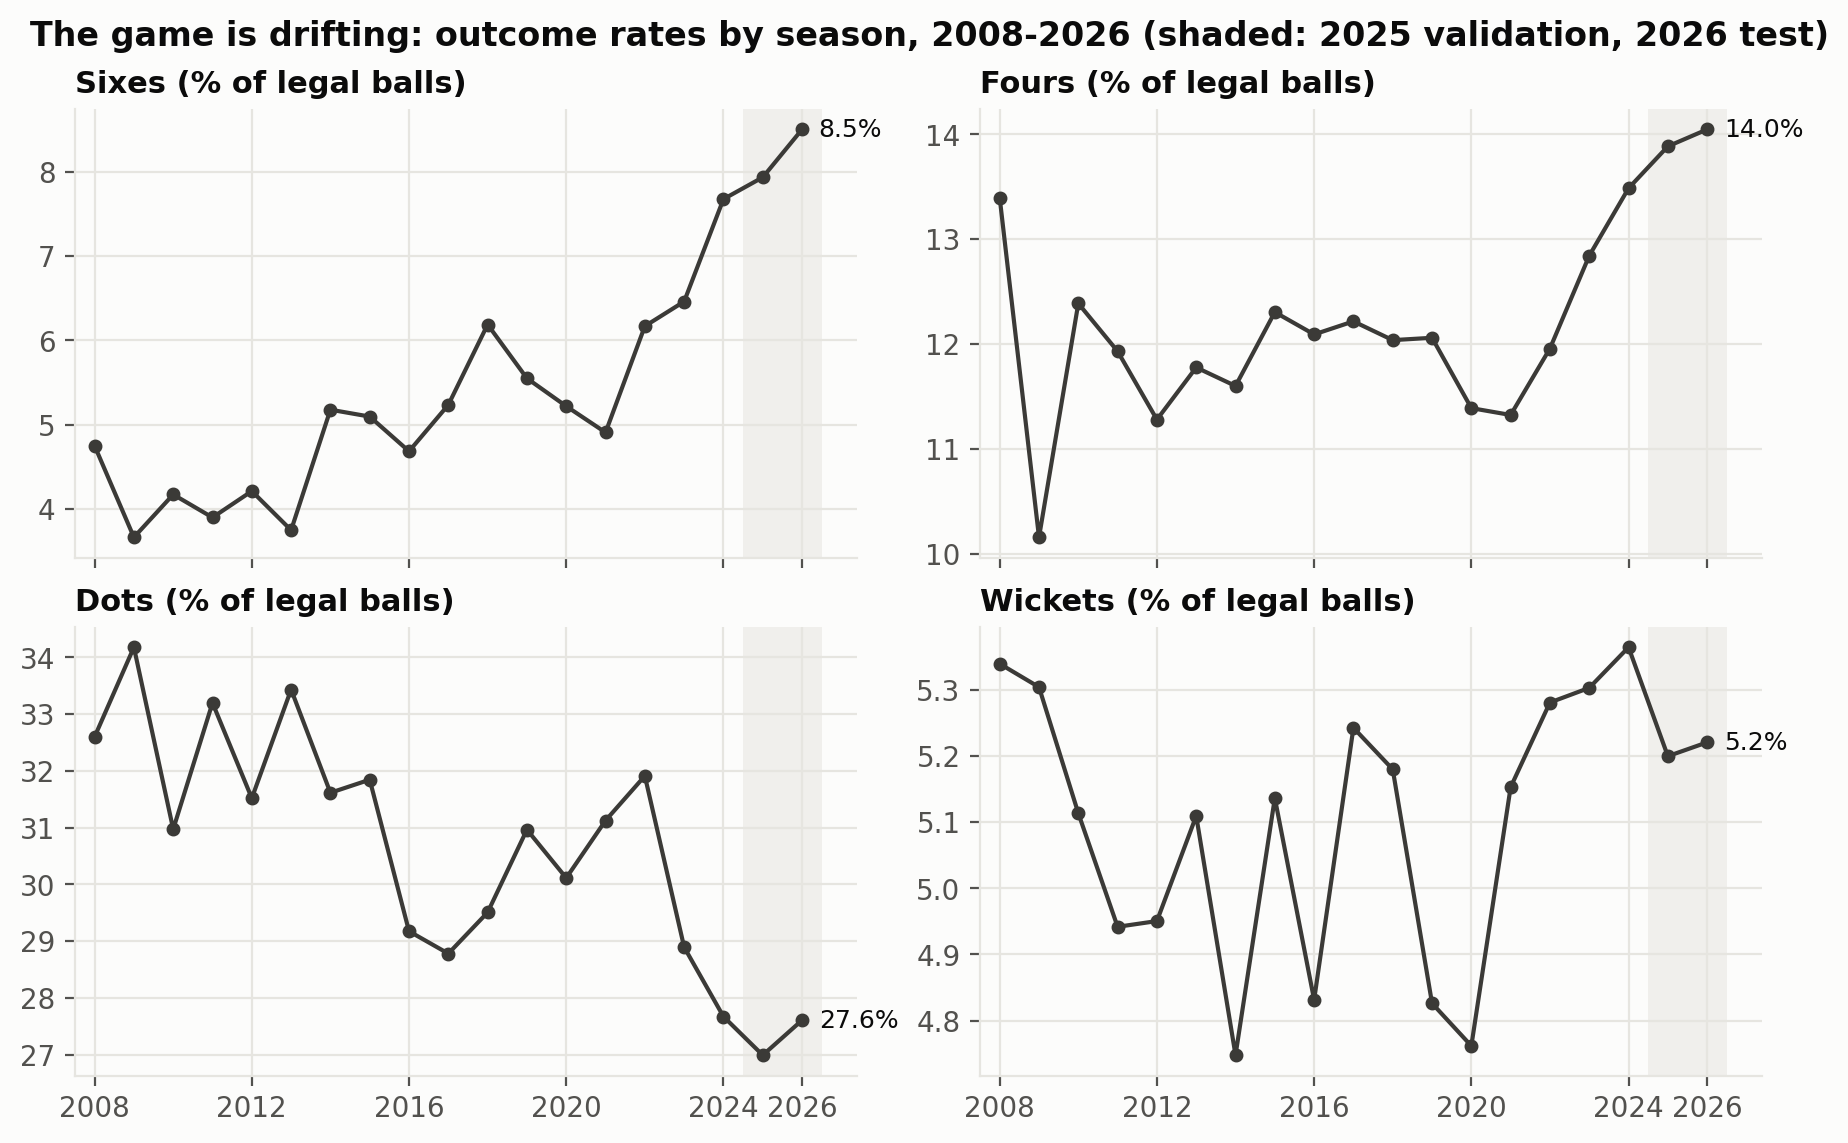

In [10]:
# ===== W6b. Drift by season (COPY-PASTE) =====
leg = df[(df['y'] >= 0) & df['split'].isin(['train', 'val', 'test'])]
rate = pd.crosstab(leg['year'], leg['y'], normalize='index') * 100
PANELS = [(5, 'Sixes'), (4, 'Fours'), (0, 'Dots'), (6, 'Wickets')]
tr = leg[leg['split'] == 'train']['y']
print(f"six %: training 2008-2024 {100 * (tr == 5).mean():.1f} | 2025 {rate.loc[2025, 5]:.1f} | 2026 {rate.loc[2026, 5]:.1f}")
# proposal: 5.1 | 7.9 | 8.5

def draw_drift(T):
    fig, axes = plt.subplots(2, 2, figsize=(9, 5.6), sharex=True, layout='constrained')
    for ax, (k, name) in zip(axes.flat, PANELS):
        s = rate[k]
        ax.axvspan(2024.5, 2026.5, color=T['band'], zorder=0, lw=0)
        ax.plot(s.index, s.values, color=T['data'], marker='o', ms=4)
        ax.set_title(f'{name} (% of legal balls)')
        ax.annotate(f'{s.iloc[-1]:.1f}%', (s.index[-1], s.iloc[-1]), xytext=(6, 0),
                    textcoords='offset points', va='center', color=T['ink'], fontsize=9)
        ax.set_xlim(2007.5, 2027.4)
        ax.set_xticks([2008, 2012, 2016, 2020, 2024, 2026])
    fig.suptitle('The game is drifting: outcome rates by season, 2008-2026 (shaded: 2025 validation, 2026 test)',
                 x=0.01, ha='left', fontweight='bold')
    return fig
render(draw_drift, 'fig1_drift_by_season')

entropy (nats), 2008-2024: {'powerplay': 1.42, 'middle': 1.4, 'death': 1.6} | overs 1-15 together: 1.44
entropy (nats): {'2008-2025': {'powerplay': 1.43, 'middle': 1.41, 'death': 1.6}, '2026': {'powerplay': 1.52, 'middle': 1.46, 'death': 1.6}}
                          0     1    2    3     4     6    W
          match_phase                                       
2008-2025 powerplay    42.8  28.2  4.3  0.5  16.4   3.9  3.9
          middle       27.8  46.9  6.8  0.2   9.3   4.7  4.3
          death        20.4  41.2  9.1  0.3  12.1   8.4  8.4
2026      powerplay    37.2  27.4  3.6  0.3  18.6   8.5  4.4
          middle       23.9  46.4  6.1  0.1  11.3   7.5  4.6
          death        21.8  39.4  6.9  0.2  13.3  10.7  7.7
change, 2026 minus 2008-2025 (points):
               0    1    2    3    4    6    W
match_phase                                   
powerplay   -5.6 -0.8 -0.7 -0.2  2.3  4.7  0.4
middle      -3.9 -0.5 -0.7 -0.1  2.0  2.7  0.4
death        1.3 -1.8 -2.2 -0.1  1.1  2.2

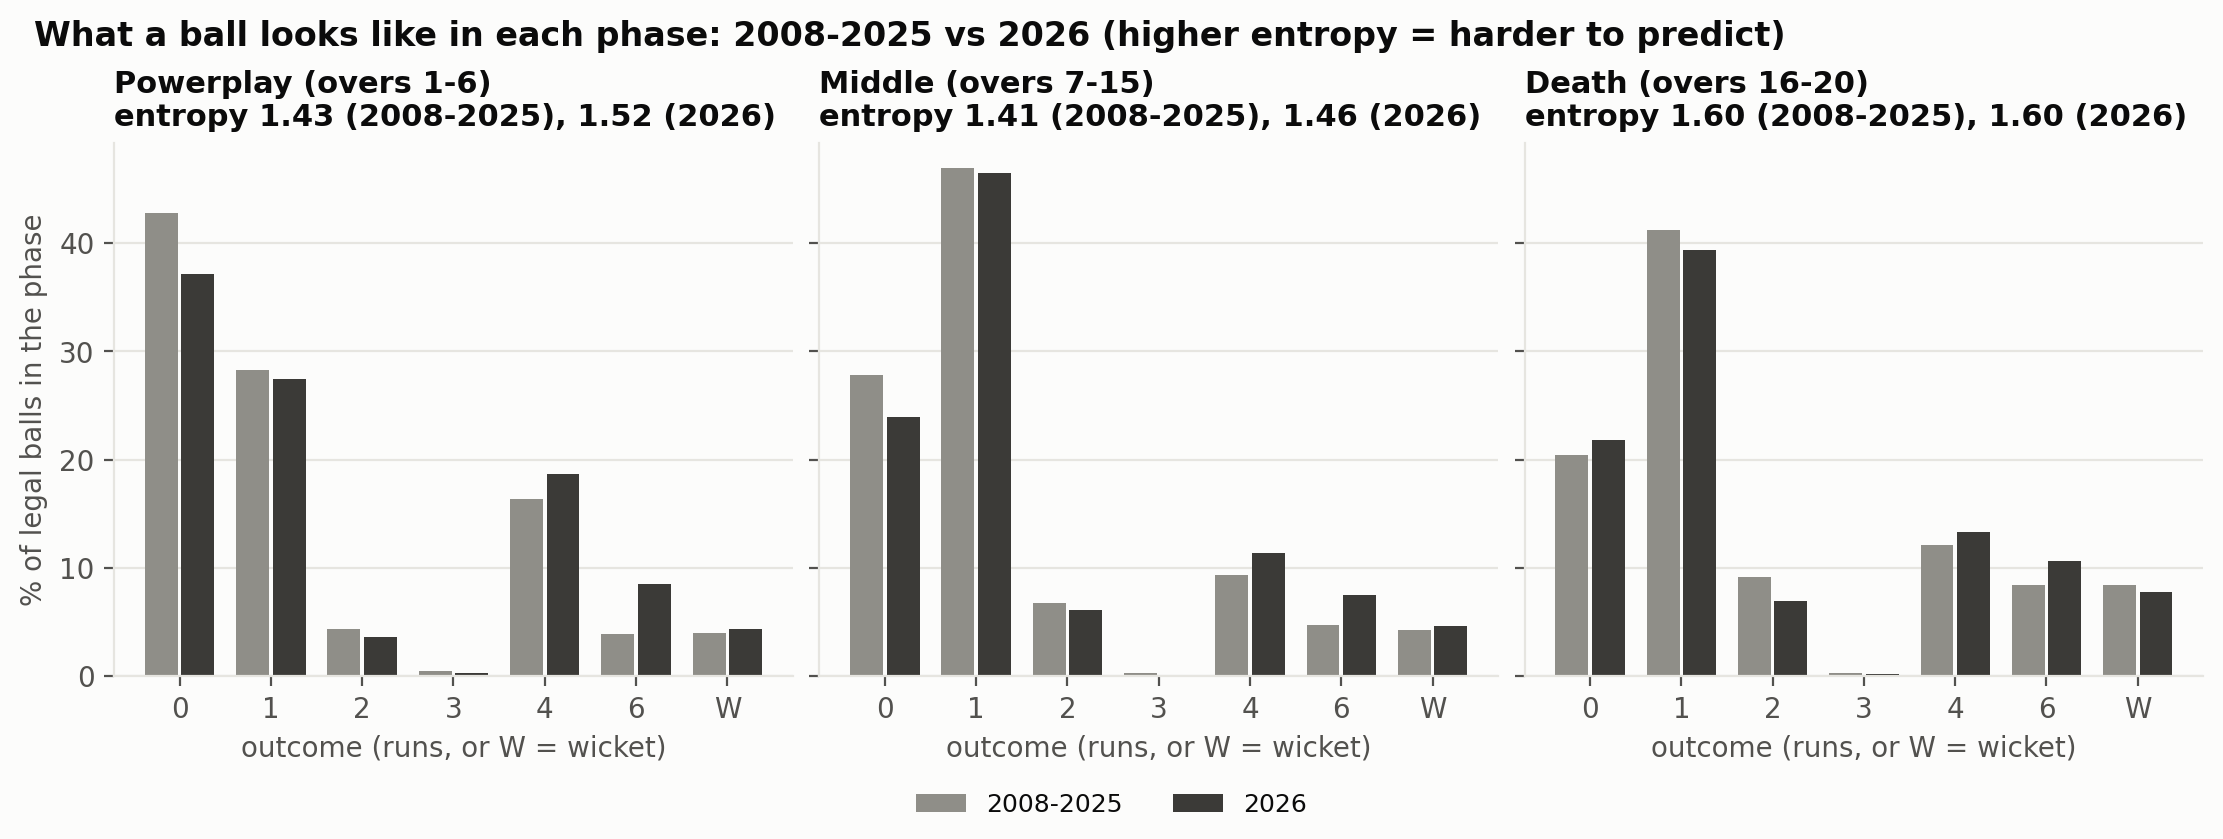

In [16]:
# ===== W6c. Outcome shares by phase, 2008-2025 vs 2026 (COPY-PASTE) — v2, Nov 4: one panel per phase =====
PH = ['powerplay', 'middle', 'death']
PH_TITLE = {'powerplay': 'Powerplay (overs 1-6)', 'middle': 'Middle (overs 7-15)', 'death': 'Death (overs 16-20)'}
THEME['light']['past'], THEME['dark']['past'] = '#8f8e88', '#77766f'    # grey for 2008-2025 (3:1 contrast in both themes)

def entropy(p): p = p[p > 0] / 100; return float(-(p * np.log(p)).sum())
def shares(rows):                                         # % of legal balls per outcome, one row per phase
    return pd.crosstab(rows['match_phase'], rows['y'], normalize='index').reindex(index=PH, columns=range(K), fill_value=0) * 100

trn = leg[leg['split'] == 'train']                        # proposal check uses the training seasons, 2008-2024
early = trn[trn['match_phase'] != 'death']['y'].value_counts(normalize=True).values * 100
print('entropy (nats), 2008-2024:', {ph: round(entropy(v), 2) for ph, v in zip(PH, shares(trn).values)},
      '| overs 1-15 together:', round(entropy(early), 2))   # proposal: death 1.60, earlier overs about 1.41

PERIODS = [('2008-2025', shares(leg[leg['year'] <= 2025])), ('2026', shares(leg[leg['year'] == 2026]))]
ENT = {lab: {ph: entropy(S.loc[ph].values) for ph in PH} for lab, S in PERIODS}
print('entropy (nats):', {lab: {ph: round(v, 2) for ph, v in e.items()} for lab, e in ENT.items()})
print(pd.concat({lab: S for lab, S in PERIODS}).set_axis(NAMES, axis=1).round(1))          # shares, %
print('change, 2026 minus 2008-2025 (points):')
print((PERIODS[1][1] - PERIODS[0][1]).set_axis(NAMES, axis=1).round(1))

def draw_phase(T):
    fig, axes = plt.subplots(1, 3, figsize=(11, 4.1), sharey=True, layout='constrained')
    x, w = np.arange(K), 0.4
    col = {'2008-2025': T['past'], '2026': T['data']}
    for ax, ph in zip(axes, PH):
        for j, (lab, S) in enumerate(PERIODS):
            ax.bar(x + (j - 0.5) * w, S.loc[ph].values, width=w - 0.04, color=col[lab], label=lab)
        ax.set_xticks(x, NAMES)
        ax.grid(axis='x', visible=False)
        ax.set_title(f"{PH_TITLE[ph]}\nentropy {ENT['2008-2025'][ph]:.2f} (2008-2025), {ENT['2026'][ph]:.2f} (2026)")
        ax.set_xlabel('outcome (runs, or W = wicket)')
    axes[0].set_ylabel('% of legal balls in the phase')
    fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=2, fontsize=9)
    fig.suptitle('What a ball looks like in each phase: 2008-2025 vs 2026 (higher entropy = harder to predict)',
                 x=0.01, ha='left', fontweight='bold')
    return fig
render(draw_phase, 'fig2_outcomes_by_phase')

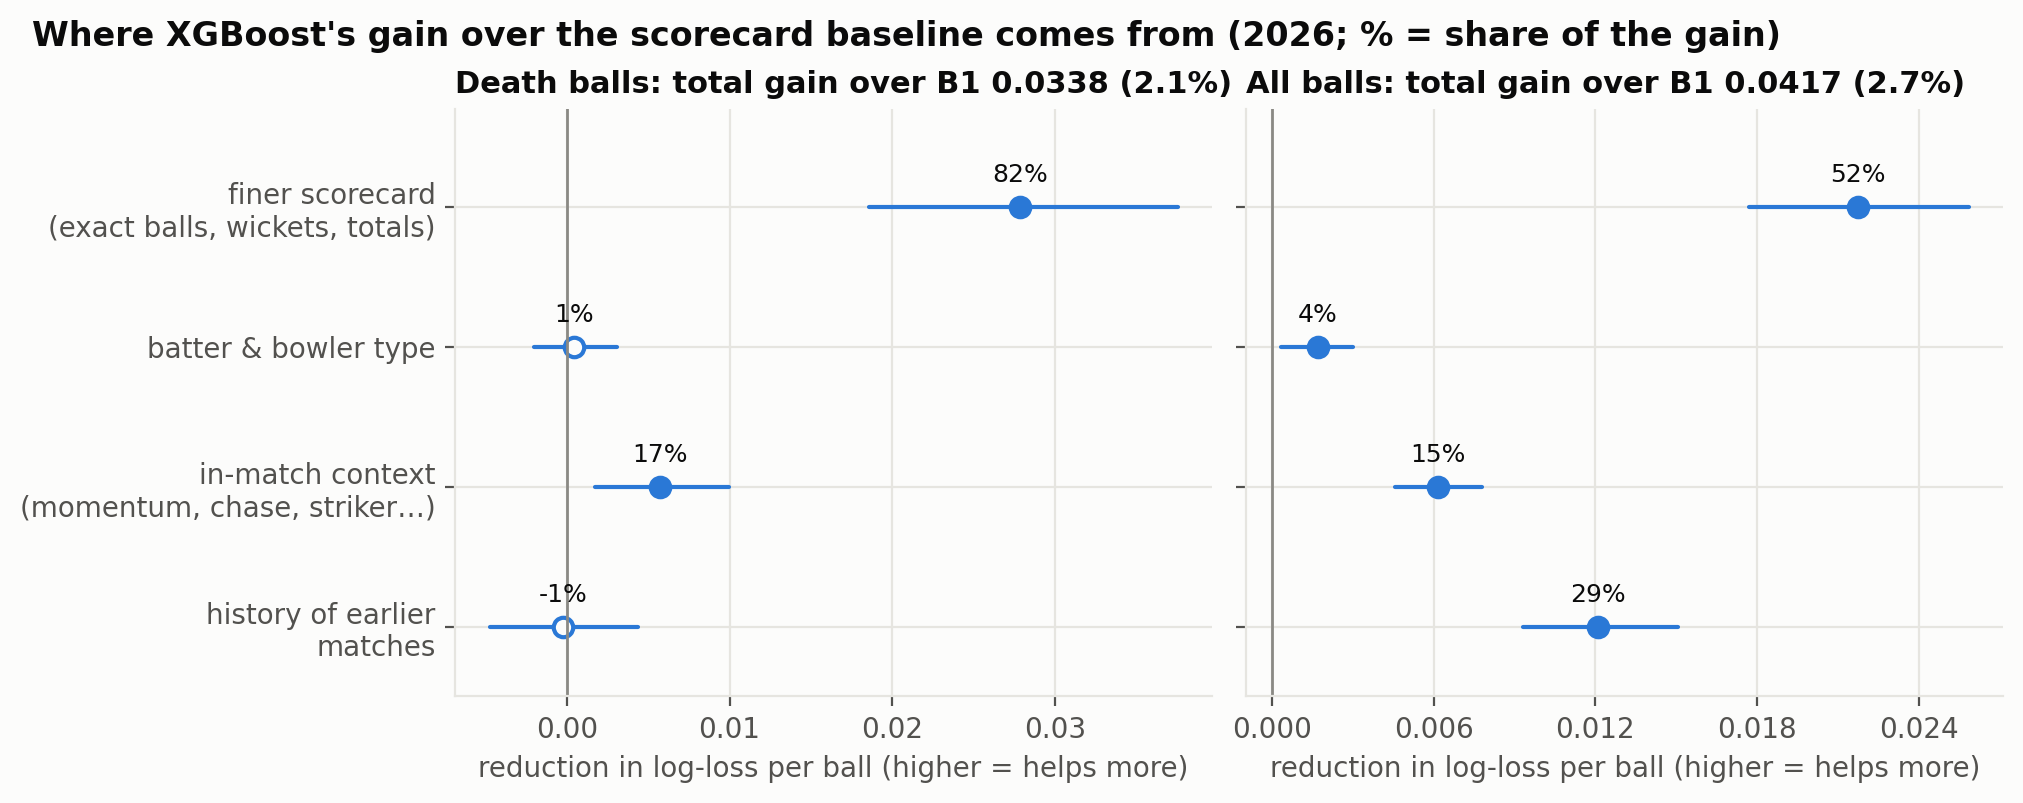

In [12]:
# ===== W6d. Ladder (COPY-PASTE) =====
lad = pd.read_csv(DATA + 'ladder_2026.csv').query("metric == 'logloss'")
STEPS = ['scorecard state', '+ player type', '+ in-match context', '+ history (X-hist)']
STEP_LABEL = ['finer scorecard\n(exact balls, wickets, totals)', 'batter & bowler type',
              'in-match context\n(momentum, chase, striker…)', 'history of earlier\nmatches']

def draw_ladder(T):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True, layout='constrained')
    for ax, balls in zip(axes, ['death', 'all']):
        r = lad[lad['balls'] == balls].set_index('rung').loc[STEPS]
        tot = lad[(lad['balls'] == balls)].set_index('rung')
        gain = tot.loc['B1', 'value'] - tot.loc['+ history (X-hist)', 'value']
        yv = np.arange(len(STEPS))[::-1]
        interval_marks(ax, yv, -r['step'], -r['step_high'], -r['step_low'], T['model']['xgb'], (r['step_high'] < 0).values)
        for yy, red, sh in zip(yv, -r['step'], r['share_of_gain_over_B1']):
            ax.annotate(f'{100 * sh:.0f}%', (red, yy), xytext=(0, 9), textcoords='offset points',
                        ha='center', fontsize=9, color=T['ink'])
        ax.axvline(0, color=T['zero'], lw=1)
        ax.set_yticks(yv, STEP_LABEL)
        ax.set_ylim(-0.5, len(STEPS) - 0.3)                      # room for the % label on the top row
        ax.xaxis.set_major_locator(MaxNLocator(5))
        ax.set_xlabel('reduction in log-loss per ball (higher = helps more)')
        ax.set_title(f"{'Death balls' if balls == 'death' else 'All balls'}: "
                     f"total gain over B1 {gain:.4f} ({100 * gain / tot.loc['B1', 'value']:.1f}%)")
    fig.suptitle('Where XGBoost\'s gain over the scorecard baseline comes from (2026; % = share of the gain)',
                 x=0.01, ha='left', fontweight='bold')
    return fig
render(draw_ladder, 'fig3_death_ladder')

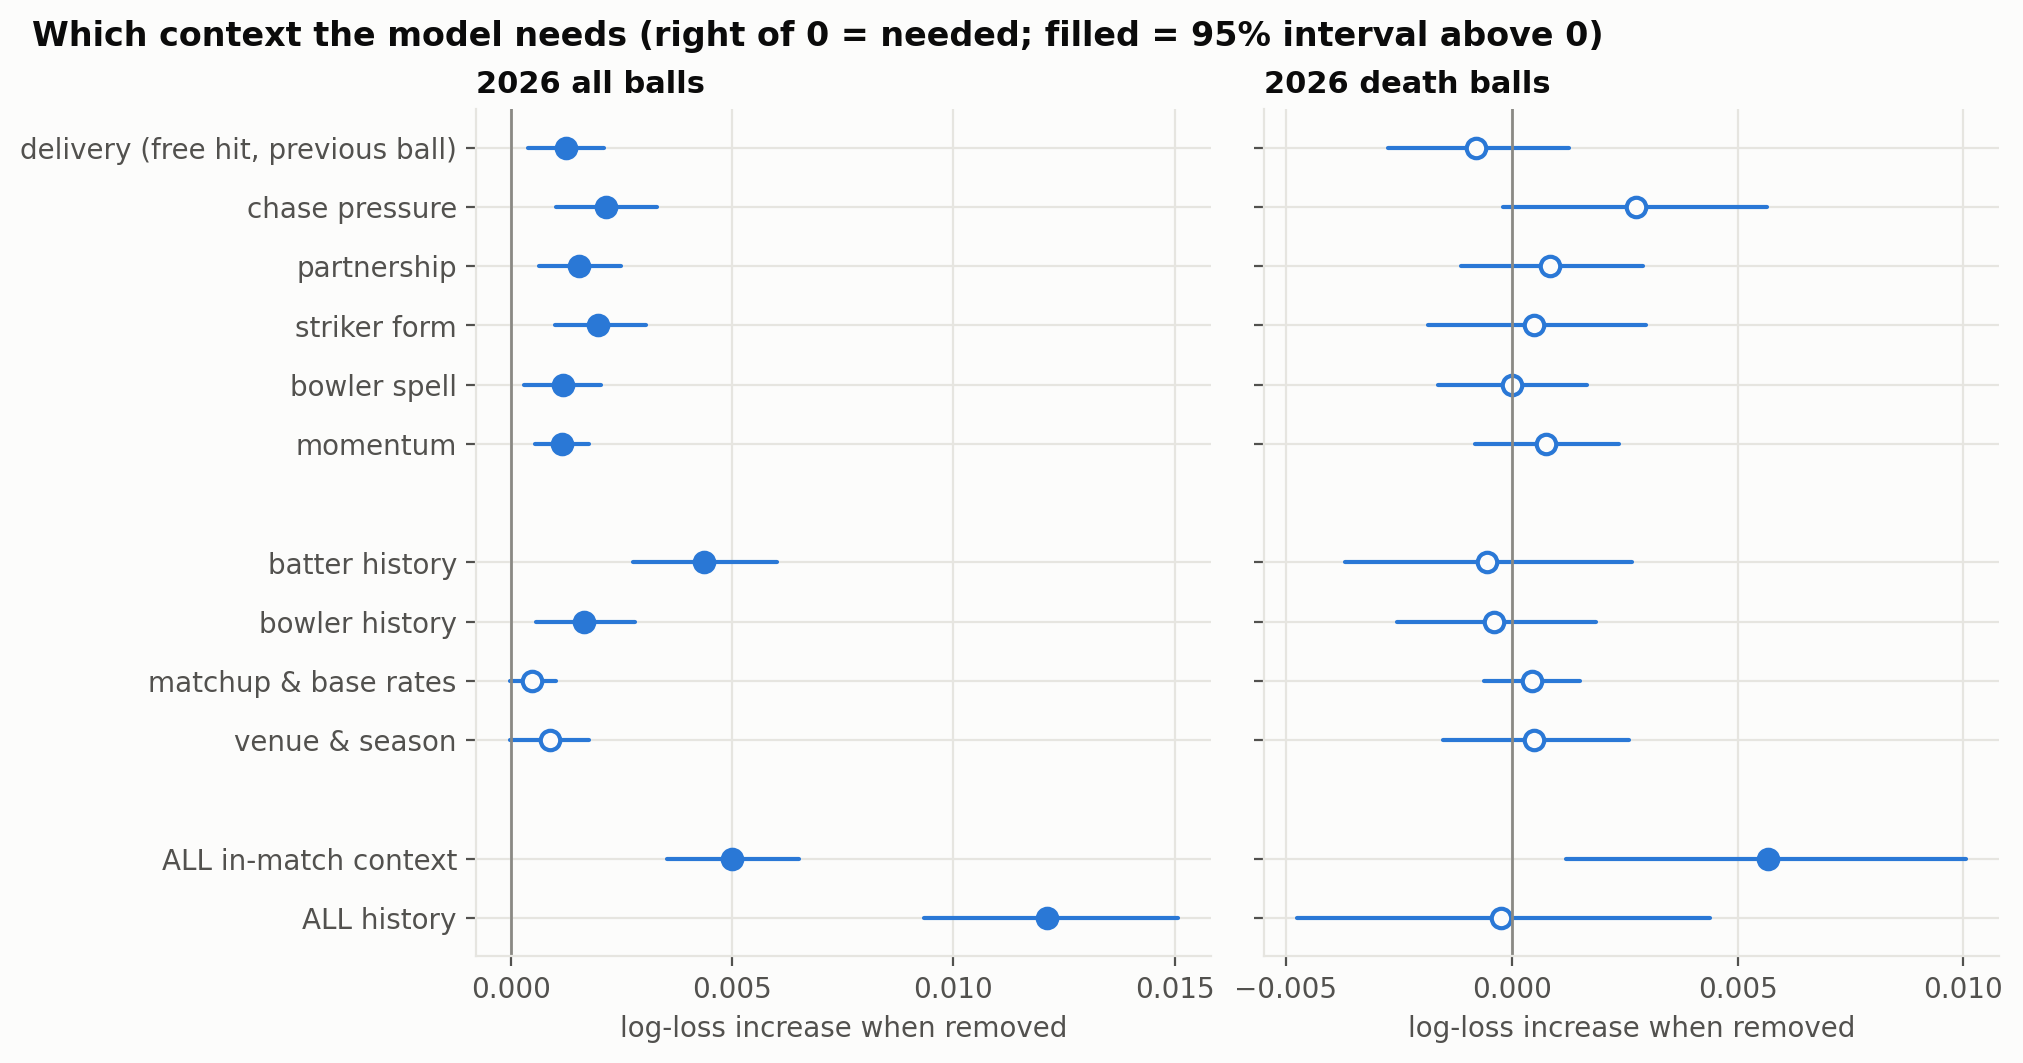

In [13]:
# ===== W6e. Ablation intervals (COPY-PASTE) =====
ab = pd.read_csv(DATA + 'ablation_groups.csv').query('season == 2026').rename(columns={'group': 'what'})
bl = pd.read_csv(DATA + 'ablation_blocks.csv').query('season == 2026').rename(columns={'block': 'what'})
abl = pd.concat([ab, bl])
ROWS = [('delivery', 'delivery (free hit, previous ball)'), ('chase', 'chase pressure'), ('partnership', 'partnership'),
        ('striker', 'striker form'), ('bowler_spell', 'bowler spell'), ('momentum', 'momentum'),
        ('hist_8_batter', 'batter history'), ('hist_9_bowler', 'bowler history'),
        ('hist_10_base', 'matchup & base rates'), ('hist_11_venue_season', 'venue & season'),
        ('all_inmatch_context', 'ALL in-match context'), ('all_history', 'ALL history')]

def draw_ablation(T):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5.2), sharey=True, layout='constrained')
    yv = np.array([13, 12, 11, 10, 9, 8, 6, 5, 4, 3, 1, 0])          # gaps separate in-match, history, blocks
    for ax, balls in zip(axes, ['all', 'death']):
        r = abl[abl['balls'] == balls].set_index('what').loc[[k for k, _ in ROWS]]
        interval_marks(ax, yv, r['loss_if_dropped'], r['low'], r['high'], T['model']['xgb'], (r['low'] > 0).values)
        ax.axvline(0, color=T['zero'], lw=1)
        ax.set_yticks(yv, [lab for _, lab in ROWS])
        ax.xaxis.set_major_locator(MaxNLocator(4))
        ax.set_xlabel('log-loss increase when removed')
        ax.set_title(f"2026 {'all balls' if balls == 'all' else 'death balls'}")
    fig.suptitle('Which context the model needs (right of 0 = needed; filled = 95% interval above 0)',
                 x=0.01, ha='left', fontweight='bold')
    return fig
render(draw_ablation, 'fig4_ablation')

Dots: distinct B1 values 8 | points {'xgb': 10, 'lr': 10, 'b1': 6}
Sixes: distinct B1 values 8 | points {'xgb': 10, 'lr': 10, 'b1': 6}
Wickets: distinct B1 values 8 | points {'xgb': 10, 'lr': 10, 'b1': 7}


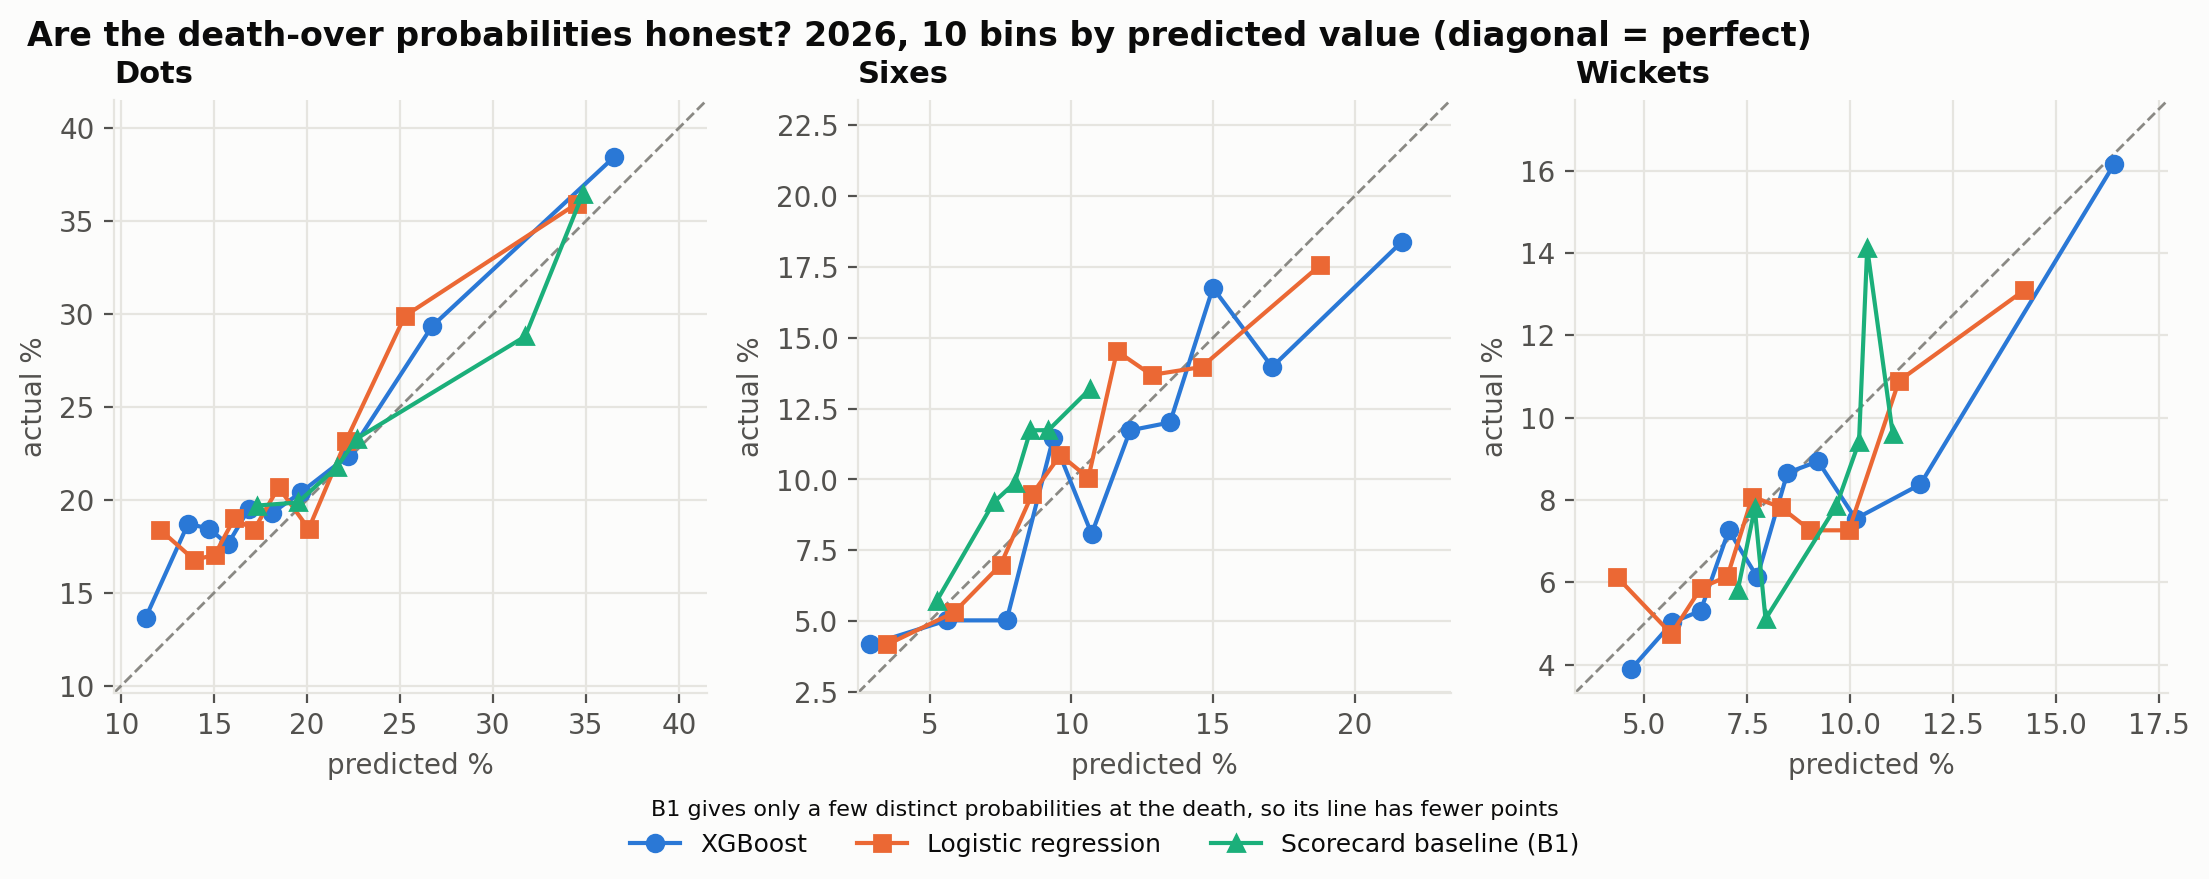

In [17]:
# ===== W6f. Death reliability (COPY-PASTE) — v2, Nov 4: ties stay in one bin =====
CLS = [(0, 'Dots'), (5, 'Sixes'), (6, 'Wickets')]
yd_ = y[death]

def rel_points(p, hit, n_bins=10):
    # v2: cut at the deciles of the predicted VALUE, so balls with the same prediction always share a bin.
    # (v1 cut by rank, which split B1's tied balls by match order and drew match-to-match noise as a zigzag.)
    b = pd.qcut(p, n_bins, labels=False, duplicates='drop')
    g = pd.DataFrame({'b': b, 'p': p, 'hit': hit}).groupby('b')
    return 100 * g['p'].mean().values, 100 * g['hit'].mean().values

for k, name in CLS:                                             # how many points each model gets
    print(f'{name}: distinct B1 values {len(np.unique(P["b1"][death][:, k]))} | points',
          {m: len(rel_points(P[m][death][:, k], (yd_ == k).astype(float))[0]) for m in P})

def draw_rel(T):
    fig, axes = plt.subplots(1, 3, figsize=(11, 4.3), layout='constrained')
    for ax, (k, name) in zip(axes, CLS):
        hit = (yd_ == k).astype(float)
        pts = {m: rel_points(P[m][death][:, k], hit) for m in P}
        top = 1.08 * max(max(a.max(), b.max()) for a, b in pts.values())
        low = 0.85 * min(min(a.min(), b.min()) for a, b in pts.values())
        ax.plot([low, top], [low, top], color=T['zero'], lw=1, ls='--')
        for m, (px, ob) in pts.items():
            ax.plot(px, ob, color=T['model'][m], marker=MARKER[m], ms=6, lw=1.5, label=MODEL_NAME[m])
        ax.set_xlim(low, top); ax.set_ylim(low, top); ax.set_aspect('equal')
        ax.set_title(name); ax.set_xlabel('predicted %'); ax.set_ylabel('actual %')
    fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=3, fontsize=9,
               title='B1 gives only a few distinct probabilities at the death, so its line has fewer points',
               title_fontsize=8)
    fig.suptitle('Are the death-over probabilities honest? 2026, 10 bins by predicted value (diagonal = perfect)',
                 x=0.01, ha='left', fontweight='bold')
    return fig
render(draw_rel, 'fig5_death_reliability')

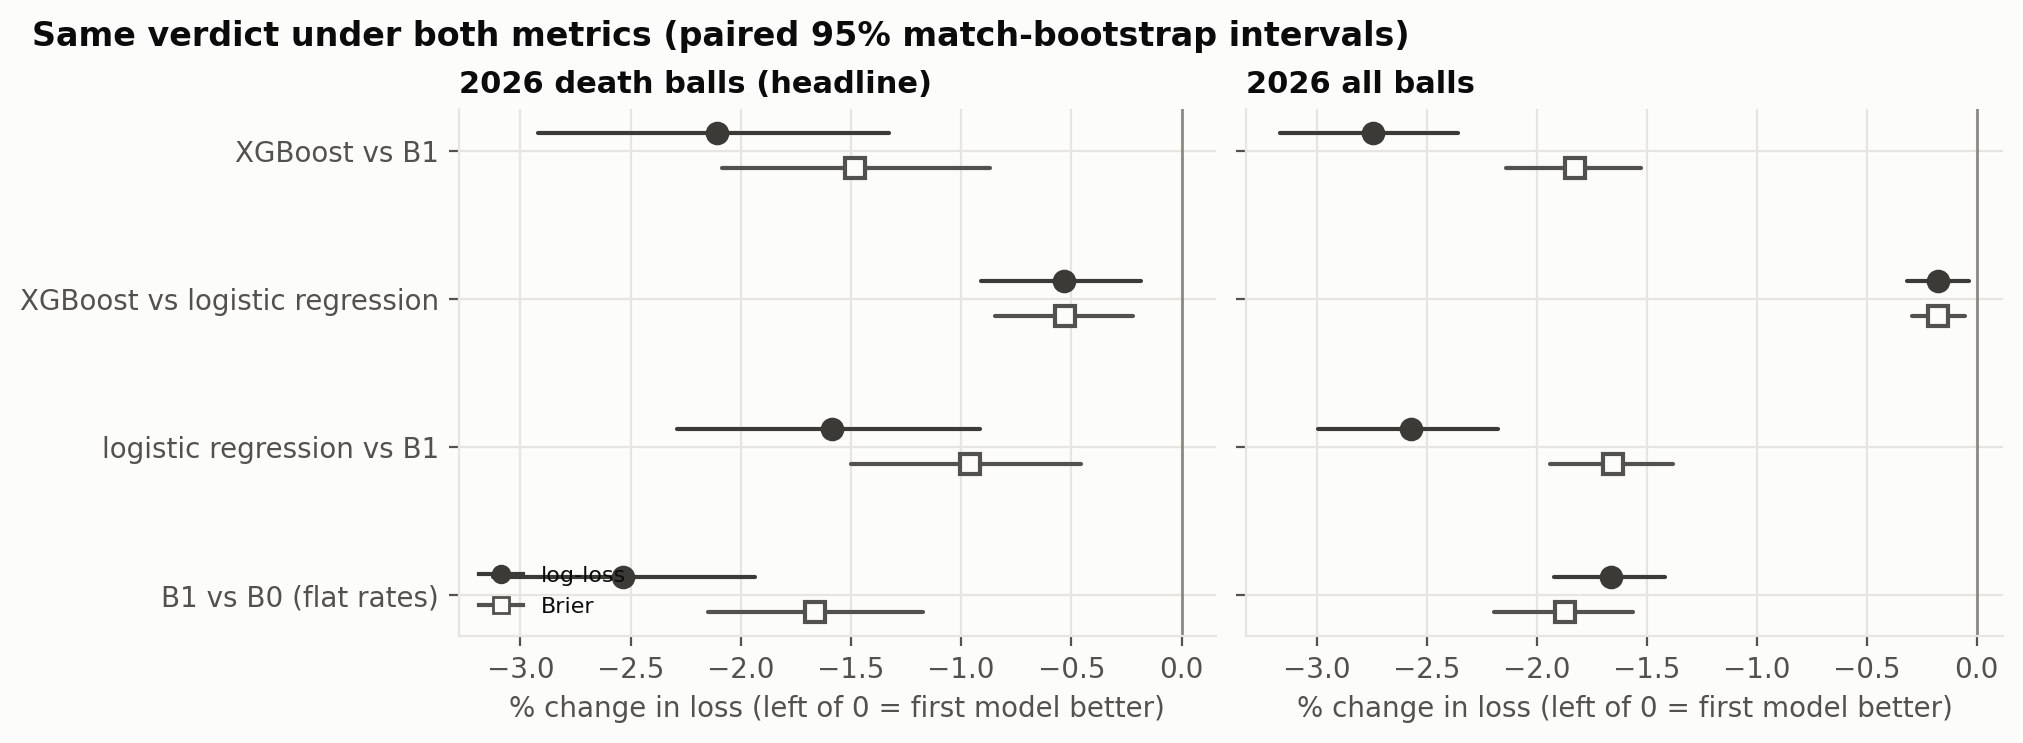

In [15]:
# ===== W6g. Headline, log-loss vs Brier (COPY-PASTE) =====
mc = pd.read_csv(DATA + 'metric_check_2026.csv')
for c in ('low', 'high'):
    mc[c + '_pct'] = 100 * mc[c] / mc['B']
PAIRS = [('X-hist - B1', 'XGBoost vs B1'), ('X-hist - LR (B2-hist +V)', 'XGBoost vs logistic regression'),
         ('LR (B2-hist +V) - B1', 'logistic regression vs B1'), ('B1 - B0', 'B1 vs B0 (flat rates)')]

def draw_headline(T):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, layout='constrained')
    yv = np.arange(len(PAIRS))[::-1]
    for ax, balls in zip(axes, ['death', 'all']):
        for metric, dy, mk, col in [('logloss', 0.12, 'o', T['data']), ('brier', -0.12, 's', T['ink2'])]:
            r = mc[(mc['balls'] == balls) & (mc['metric'] == metric)].set_index('pair').loc[[p for p, _ in PAIRS]]
            for yy, m, l, h in zip(yv + dy, r['pct'], r['low_pct'], r['high_pct']):
                ax.plot([l, h], [yy, yy], color=col, lw=1.5, solid_capstyle='round')
                ax.plot(m, yy, marker=mk, ms=7, color=col, mew=1.5,
                        mfc=col if metric == 'logloss' else T['surface'])
            ax.plot([], [], marker=mk, color=col, mfc=col if metric == 'logloss' else T['surface'],
                    lw=1.5, label='log-loss' if metric == 'logloss' else 'Brier')
        ax.axvline(0, color=T['zero'], lw=1)
        ax.set_yticks(yv, [lab for _, lab in PAIRS])
        ax.set_xlabel('% change in loss (left of 0 = first model better)')
        ax.set_title(f"2026 {'death balls (headline)' if balls == 'death' else 'all balls'}")
    axes[0].legend(loc='lower left', fontsize=8)
    fig.suptitle('Same verdict under both metrics (paired 95% match-bootstrap intervals)', x=0.01, ha='left', fontweight='bold')
    return fig
render(draw_headline, 'fig6_headline_metrics')

In [19]:
# ===== W7-pre. What's in data/ (COPY-PASTE) =====
import glob, os
print(sorted(os.path.basename(f) for f in glob.glob(DATA + '*')))
for f in sorted(glob.glob(DATA + '*.csv')):
    if any(w in f.lower() for w in ('player', 'batter', 'bowler')):
        print('\n' + os.path.basename(f)); print(pd.read_csv(f).head(5).to_string())

['ablation_blocks.csv', 'ablation_groups.csv', 'ablation_preds.npz', 'archive', 'b2_models.joblib', 'b2hist_models.joblib', 'balls_2026_explained.parquet', 'bpw_bands_2026.csv', 'bundle_2025.parquet', 'bundle_2026.parquet', 'calibration.json', 'ece_2026.csv', 'failure_calibration_2025.csv', 'failure_calibration_2026.csv', 'feature_list.json', 'freeze.json', 'ipl_features.parquet', 'ladder_2026.csv', 'ladder_preds_2026.npz', 'matches_2026.csv', 'matchup_ablation.csv', 'metric_check_2026.csv', 'models_2026.joblib', 'paired_2026.csv', 'player_metadata.csv', 'players_bat_2025.csv', 'players_bat_2026.csv', 'players_bowl_2025.csv', 'players_bowl_2026.csv', 'preregistered_2026.csv', 'prog3.csv', 'prog_sg1_end.csv', 'prog_sg2_end.csv', 'push_by_feature_2026.csv', 'push_by_group_2026.csv', 'push_death_2026.parquet', 'push_intervals_2026.csv', 'rain_affected_matches.csv', 'rain_scored.csv', 'rain_scored_all50.csv', 'results.csv', 'results_2026.csv', 'site', 'slices_2025.csv', 'slices_2026.csv', 

In [20]:
# ===== W7. Player tables for the results page (COPY-PASTE) =====
REN = {'gain vs B1': 'gain', 'gain low': 'gain_low', 'gain high': 'gain_high', 'LL X-hist': 'll_xhist',
       'SR above exp': 'sr_above_exp', 'SR low': 'sr_low', 'SR high': 'sr_high', 'runs above exp': 'runs_above_exp',
       'sixes above exp': 'sixes_above_exp', 'wkts above exp': 'wkts_above_exp', 'wkts low': 'wkts_low', 'wkts high': 'wkts_high'}
MIN_BALLS = {'bat': 150, 'bowl': 120}
meta = pd.read_csv(DATA + 'player_metadata.csv').rename(columns={'name': 'player'}).drop_duplicates('player')

def load(kind):
    t = pd.read_csv(DATA + f'players_{kind}_2026.csv').rename(columns=REN)
    t = t[t['balls'] >= MIN_BALLS[kind]].merge(meta, on='player', how='left')
    t['gain_pct'] = 100 * t['gain'] / (t['ll_xhist'] - t['gain'])    # vs B1's loss on the same balls (B1 = X-hist − gain)
    print(f"{kind}: {len(t)} players with {MIN_BALLS[kind]}+ balls | metadata found for {t['batting_hand'].notna().sum()}")
    return t

bat, bowl = load('bat'), load('bowl')
TABLE = {'bat': bat, 'bowl': bowl}
# name: (table, sort column, ascending, title for the page). gain = X-hist loss − B1 loss per ball, so lower = read better.
LISTS = {'bat_best_read':      ('bat', 'gain', True, 'Batters XGBoost reads best'),
         'bat_worst_read':     ('bat', 'gain', False, 'Batters XGBoost reads worst'),
         'bat_runs_above_exp': ('bat', 'runs_above_exp', False, 'Batters who beat the expected runs most'),
         'bowl_best_read':     ('bowl', 'gain', True, 'Bowlers XGBoost reads best'),
         'bowl_worst_read':    ('bowl', 'gain', False, 'Bowlers XGBoost reads worst'),
         'bowl_runs_below_exp': ('bowl', 'runs_above_exp', True, 'Bowlers who conceded least against expected')}
KEEP = ['player', 'batting_hand', 'bowler_cat', 'balls', 'matches', 'gain', 'gain_low', 'gain_high', 'gain_pct', 'll_xhist',
        'sr_above_exp', 'sr_low', 'sr_high', 'runs_above_exp', 'sixes_above_exp', 'wkts_above_exp', 'wkts_low', 'wkts_high']

def records(t):
    t = t[KEEP].round(4).astype(object)
    return t.where(t.notna(), None).to_dict('records')       # NaN -> null, because browsers can't read NaN in JSON

def summary(t):
    return {'players': len(t), 'median_gain': round(float(t['gain'].median()), 4),
            'gain_iqr': round(float(t['gain'].quantile(.75) - t['gain'].quantile(.25)), 4),
            'read_better_than_B1': int((t['gain_high'] < 0).sum()),     # whole interval below 0
            'read_worse_than_B1': int((t['gain_low'] > 0).sum())}

site_players = {
    'season': 2026, 'min_balls': MIN_BALLS,
    'notes': ['Descriptive and post hoc: looked at after the single scoring run; nothing was changed because of it.',
              'gain = XGBoost log-loss minus B1 log-loss per ball on this player\'s balls (negative = XGBoost reads them better).',
              'Intervals come from few matches per player, so they run a little narrow.',
              'Expected runs inherit the season-wide over-prediction (about 0.03 runs per ball), '
              'so compare players with each other, not with zero.'],
    'summary': {k: summary(t) for k, t in TABLE.items()},
    'lists': {}}
for name, (kind, col, asc, title) in LISTS.items():
    top = TABLE[kind].sort_values(col, ascending=asc).head(5)
    site_players['lists'][name] = {'title': title, 'sorted_by': col, 'players': records(top)}
    print(f'\n{title} (by {col}):')
    print(top[['player', 'balls', 'gain', 'gain_low', 'gain_high', 'gain_pct', 'sr_above_exp', 'runs_above_exp']]
          .round(3).to_string(index=False))
print('\nsummary:', site_players['summary'])

with open(OUT + 'players_2026.json', 'w') as f:
    json.dump(site_players, f, indent=1, allow_nan=False, default=lambda o: o.item())
print('saved', OUT + 'players_2026.json')

bat: 44 players with 150+ balls | metadata found for 44
bowl: 61 players with 120+ balls | metadata found for 57

Batters XGBoost reads best (by gain):
         player  balls   gain  gain_low  gain_high  gain_pct  sr_above_exp  runs_above_exp
  V Suryavanshi    312 -0.189    -0.272     -0.105   -10.653        47.478         148.131
       FH Allen    156 -0.176    -0.224     -0.124   -10.027        44.077          68.760
Abhishek Sharma    275 -0.127    -0.192     -0.080    -7.322        22.691          62.401
  Priyansh Arya    171 -0.121    -0.199     -0.044    -6.621        28.038          47.944
   RD Rickelton    236 -0.095    -0.144     -0.045    -5.888         1.622           3.828

Batters XGBoost reads worst (by gain):
           player  balls   gain  gain_low  gain_high  gain_pct  sr_above_exp  runs_above_exp
         SA Yadav    180  0.010    -0.043      0.046     0.678       -12.633         -22.740
    A Raghuvanshi    280 -0.002    -0.010      0.007    -0.122        -7.259